<a href="https://colab.research.google.com/github/Adedayo-py/Building-an-XGBoost-Regression-Model/blob/main/Building_an_XGBoost_Regression_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Building an XGBoost Regression Model Using the Tips Dataset
#####Machine Learning is widely used for predictive analysis in different fields.
#####In this project, an XGBoost Regression model was developed using the Tips dataset to predict the amount of tip given by customers based on factors such as total bill, gender, smoking status, day, time, and group size.

#####XGBoost (Extreme Gradient Boosting) is a powerful machine learning algorithm known for its speed, efficiency, and high prediction accuracy.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from xgboost import XGBRegressor

In [ ]:
from google.colab import files
uploaded =  files.upload()

Saving tips.csv to tips.csv


In [ ]:
df_tips = pd.read_csv("tips.csv")

df_tips.head()

,total_bill,tip,gender,smoker,day,time,size
0,2125.50,360.79,Male,No,Thur,Lunch,1
1,2727.18,259.42,Female,No,Sun,Dinner,5
2,1066.02,274.68,Female,Yes,Thur,Dinner,4
3,3493.45,337.90,Female,No,Sun,Dinner,1
4,3470.56,567.89,Male,Yes,Sun,Lunch,6


##### The dataset contains information about restaurant customers and the tips they gave.
##### The target variable is tip, while the remaining columns are used as input features.

In [ ]:
print(df_tips.shape)

df_tips.info()

df_tips.describe()

(744, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 744 entries, 0 to 743
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  744 non-null    float64
 1   tip         744 non-null    float64
 2   gender      744 non-null    object 
 3   smoker      744 non-null    object 
 4   day         744 non-null    object 
 5   time        744 non-null    object 
 6   size        744 non-null    int64  
dtypes: float64(2), int64(1), object(4)
memory usage: 40.8+ KB


,total_bill,tip,size
count,744.000000,744.000000,744.000000
mean,2165.006640,325.948091,3.180108
std,954.248806,148.778225,1.532890
min,44.690000,0.000000,1.000000
25%,1499.022500,218.000000,2.000000
50%,2102.610000,320.460000,3.000000
75%,2743.802500,415.562500,4.000000
max,5538.290000,1090.000000,6.000000


## Data Preprocessing
##### Before training the model, the dataset was preprocessed.

##### Categorical variables were converted into numerical format using One-Hot Encoding.
##### The target column was separated from the feature columns.
##### The dataset was split into training and testing sets.

In [ ]:
# Clean column names
df_tips.columns = [c.strip().lower().replace(" ", "_") for c in df_tips.columns]

# Define target
target = "tip"

# Features and target
X = df_tips.drop(columns=[target])
y = df_tips[target]

# Detect categorical and numerical columns
categorical_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()

numerical_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("num", "passthrough", numerical_cols)
    ]
)


## Splitting the Dataset



In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

## Building the XGBoost Model
##### XGBoost Regressor was used because it performs well on structured/tabular datasets and handles feature relationships effectively.

In [ ]:
model = XGBRegressor(
    n_estimators=30,
    learning_rate=0.1,
    max_depth=3,
    random_state=42,
    n_jobs=1
)

## Creating the Pipeline
##### A machine learning pipeline was created to combine preprocessing and model training into a single workflow.

In [ ]:
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", model)
])

## Training the Model

In [ ]:
pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'smoker', 'day',
                                                   'time']),
                                                 ('num', 'passthrough',
                                                  ['total_bill', 'size'])])),
                ('model',
                 XGBRegressor(base_score=None, booster=None, callbacks=None,
                              colsample_bylevel=None, colsample_bynode=None,
                              colsample_bytree=None, device=None,
                              early_stopping...
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=0.1,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=3, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, multi_strategy=None,
                              n_estimators=30, n_jobs=1, num_parallel_tree=None, ...))])

## Making Predictions

In [ ]:
predictions = pipeline.predict(X_test)

## Evaluating the Model
##### The model performance was evaluated using:

##### Mean Absolute Error (MAE)
##### Root Mean Squared Error (RMSE)
###### R² Score

In [ ]:
mae = mean_absolute_error(y_test, predictions)

rmse = np.sqrt(mean_squared_error(y_test, predictions))

r2 = r2_score(y_test, predictions)

print("MAE:", mae)
print("RMSE:", rmse)
print("R² Score:", r2)

MAE: 127.66659425057018
RMSE: 159.53737741029732
R² Score: 0.06548876421329419


## Feature Importance Visualization
##### Feature importance helps identify which variables contributed most to the prediction process.

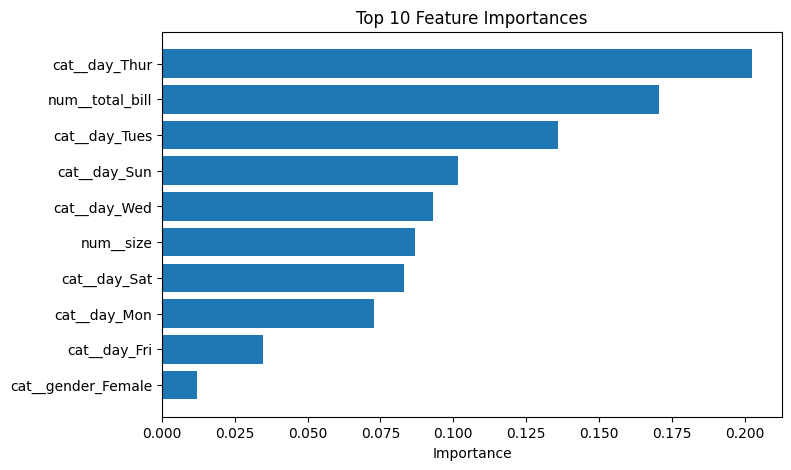

In [ ]:
feature_names = pipeline.named_steps["preprocessor"].get_feature_names_out()

importances = pipeline.named_steps["model"].feature_importances_

feat_df_tips = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
})

feat_df_tips = feat_df_tips.sort_values(by="importance", ascending=False).head(10)

plt.figure(figsize=(8,5))

plt.barh(
    feat_df_tips["feature"][::-1],
    feat_df_tips["importance"][::-1]
)

plt.xlabel("Importance")
plt.title("Top 10 Feature Importances")

plt.show()

## Conclusion
##### In this project, an XGBoost Regression model was successfully developed using the Tips dataset.

The dataset was preprocessed, categorical variables were encoded, and the model was trained and evaluated using different performance metrics.

The project demonstrates how machine learning can be applied to predict customer tipping behavior based on restaurant-related factors.